# BÀI THỰC HÀNH 1: XÂY DỰNG MẠNG NEURON ĐƠN GIẢN

<b>Hướng dẫn nộp bài:</b>
- Folder chứa toàn bộ source code, đặt tên là <b>\<MSSV\>.zip</b> với \<MSSV\> là MSSV của các bạn.
- Nộp qua course, giảng viên sẽ tạo submission sau mỗi buổi học.

Bộ dữ liệu sử dụng: MNIST dataset.

Link download: http://yann.lecun.com/exdb/mnist/.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from Load_data import MNISTDataset
from modeling import MLP1Layer, MLP3Layer
from main import evaluate

x_train, y_train, x_test, y_test = MNISTDataset().load()
print("Train:", x_train.shape, "Test:", x_test.shape)

epochs = 30
batch_size = 64
learning_rate = 0.1

Train: (60000, 784) Test: (10000, 784)


### Bài 1: Xây dựng mô hình 1-layer MLP và hàm Softmax làm activation function. Huấn luyện mô hình này sử dụng SGD làm optimizer và đánh giá trên các độ đo accuracy, precision, recall và F1-macro. Đánh giá kết quả của mô hình với từng chữ số.

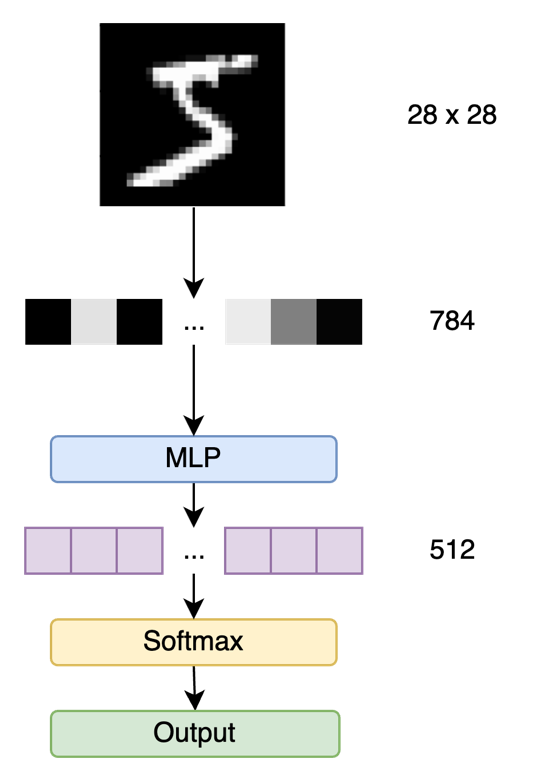

In [2]:
model1 = MLP1Layer()
model1.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, learning_rate=learning_rate)

Epoch 1/30 | loss: 0.4791 | accuracy: 0.8756
Epoch 2/30 | loss: 0.3375 | accuracy: 0.9056
Epoch 3/30 | loss: 0.3145 | accuracy: 0.9117
Epoch 4/30 | loss: 0.3023 | accuracy: 0.9154
Epoch 5/30 | loss: 0.2947 | accuracy: 0.9168
Epoch 6/30 | loss: 0.2892 | accuracy: 0.9193
Epoch 7/30 | loss: 0.2847 | accuracy: 0.9203
Epoch 8/30 | loss: 0.2811 | accuracy: 0.9217
Epoch 9/30 | loss: 0.2780 | accuracy: 0.9222
Epoch 10/30 | loss: 0.2760 | accuracy: 0.9230
Epoch 11/30 | loss: 0.2737 | accuracy: 0.9236
Epoch 12/30 | loss: 0.2717 | accuracy: 0.9248
Epoch 13/30 | loss: 0.2701 | accuracy: 0.9252
Epoch 14/30 | loss: 0.2686 | accuracy: 0.9253
Epoch 15/30 | loss: 0.2672 | accuracy: 0.9257
Epoch 16/30 | loss: 0.2660 | accuracy: 0.9268
Epoch 17/30 | loss: 0.2651 | accuracy: 0.9265
Epoch 18/30 | loss: 0.2637 | accuracy: 0.9268
Epoch 19/30 | loss: 0.2626 | accuracy: 0.9273
Epoch 20/30 | loss: 0.2617 | accuracy: 0.9276
Epoch 21/30 | loss: 0.2608 | accuracy: 0.9276
Epoch 22/30 | loss: 0.2600 | accuracy: 0.92

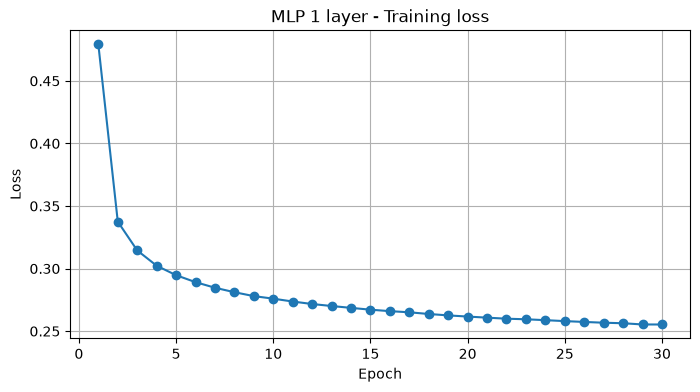

In [3]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(model1.loss_history) + 1), model1.loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP 1 layer - Training loss")
plt.grid(True)
plt.show()

In [4]:
y_pred1 = model1.predict(x_test)
evaluate(y_test, y_pred1)

Accuracy: 0.9250
Digit  Precision  Recall  F1-score
    0  0.9525     0.9816  0.9668
    1  0.9611     0.9789  0.9699
    2  0.9335     0.8983  0.9156
    3  0.9022     0.9139  0.9080
    4  0.9254     0.9348  0.9301
    5  0.9305     0.8408  0.8834
    6  0.9317     0.9541  0.9428
    7  0.9348     0.9212  0.9280
    8  0.8646     0.9045  0.8841
    9  0.9106     0.9088  0.9097
Precision-macro: 0.9247
Recall-macro: 0.9237
F1-macro: 0.9238


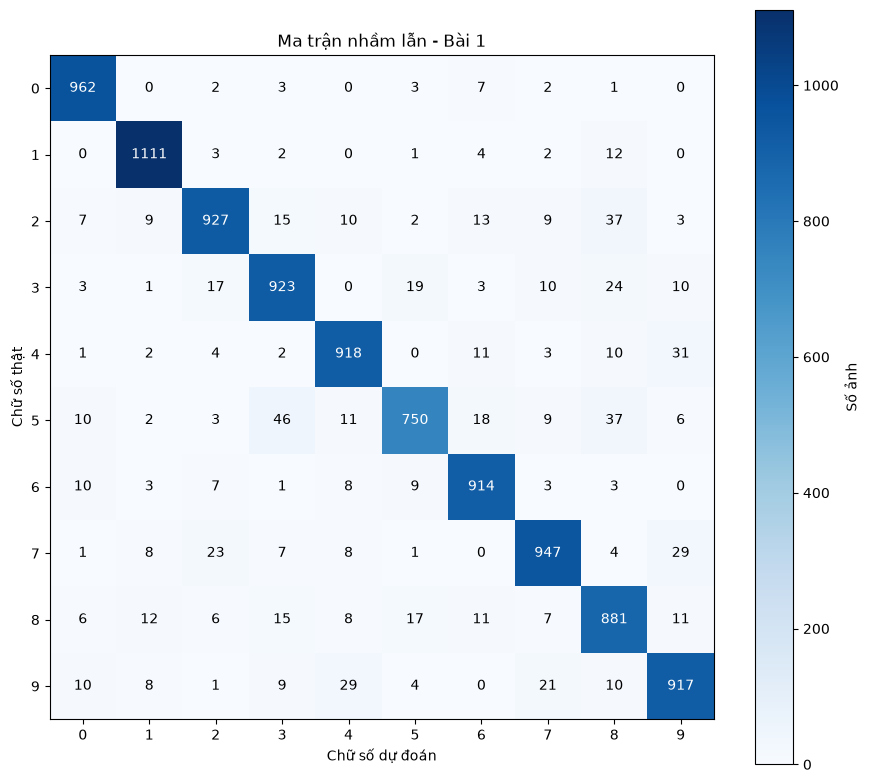

In [5]:
confusion1 = np.zeros((10, 10), dtype=int)
np.add.at(confusion1, (y_test, y_pred1), 1)

plt.figure(figsize=(9, 8))
plt.imshow(confusion1, cmap="Blues")
plt.colorbar(label="Số ảnh")
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Chữ số dự đoán")
plt.ylabel("Chữ số thật")
plt.title("Ma trận nhầm lẫn - Bài 1")
for row in range(10):
    for col in range(10):
        color = "white" if confusion1[row, col] > confusion1.max() / 2 else "black"
        plt.text(col, row, confusion1[row, col], ha="center", va="center", color=color)
plt.tight_layout()
plt.show()

Nhận xét bài 1

Sau 30 epoch, loss giảm từ 0.4791 xuống 0.2553. Accuracy trên tập test đạt 92.50%, F1-macro đạt 0.9238.

Số 0 và 1 có kết quả tốt nhất, F1 đều trên 0.96. Các số 4, 6, 7 và 9 có F1 khoảng 0.91 đến 0.94. Số 4 và 9 còn hay nhầm với nhau: 31 ảnh số 4 bị đoán thành 9 và 29 ảnh số 9 bị đoán thành 4.

Số 2 và 3 có F1 khoảng 0.91, còn nhầm sang số 8 lần lượt 37 và 24 ảnh. Số 5 và 8 có F1 thấp nhất, khoảng 0.88. Recall của số 5 chỉ đạt 0.8408, trong đó 46 ảnh bị đoán thành 3. Số 8 có precision thấp nhất vì nhiều ảnh của các số khác bị đoán thành 8.

Mô hình một lớp nhận diện được phần lớn ảnh nhưng còn sai nhiều ở số 5 và 8.

### Bài 2: Xây dựng mô hình 3-layer MLP, hàm ReLU và hàm softmax làm activation function. Trong đó activation function cho 2 layer đầu là ReLU và activation function cho layer cuối là Softmax. Huấn luyện mô hình này sử dụng SGD làm optimizer và đánh giá trên các độ đo accuracy, precision, recall và F1-macro. Đánh giá kết quả của mô hình với từng chữ số.

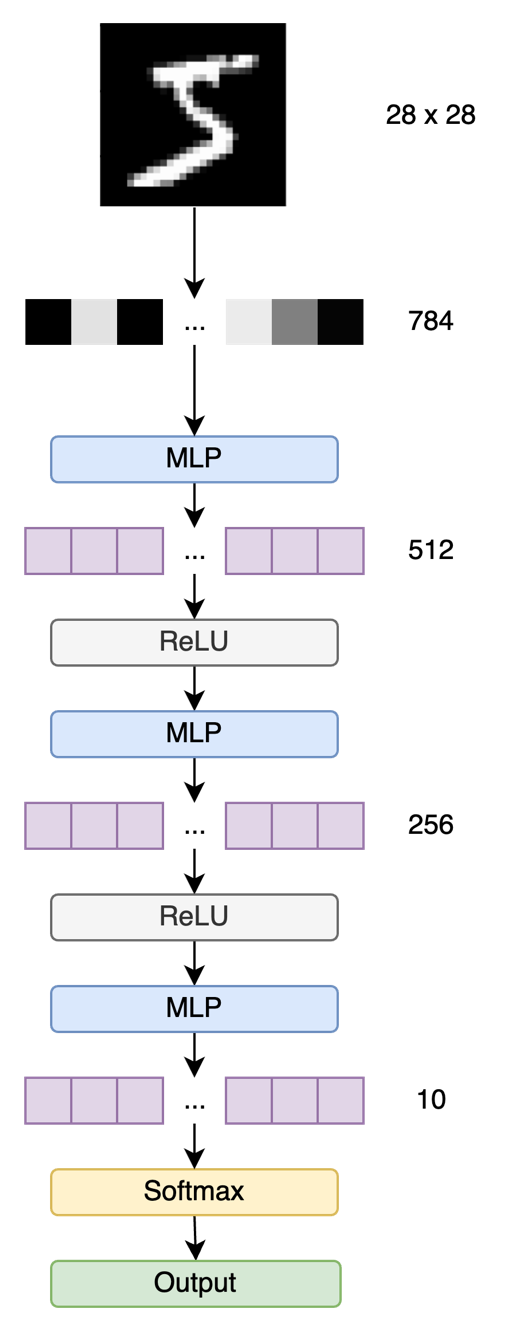

In [6]:
model2 = MLP3Layer()
model2.fit(x_train, y_train, epochs=epochs, batch_size=batch_size, learning_rate=learning_rate)

Epoch 1/30 | loss: 0.3155 | accuracy: 0.9097
Epoch 2/30 | loss: 0.1332 | accuracy: 0.9616
Epoch 3/30 | loss: 0.0915 | accuracy: 0.9729
Epoch 4/30 | loss: 0.0677 | accuracy: 0.9805
Epoch 5/30 | loss: 0.0530 | accuracy: 0.9846
Epoch 6/30 | loss: 0.0406 | accuracy: 0.9885
Epoch 7/30 | loss: 0.0320 | accuracy: 0.9910
Epoch 8/30 | loss: 0.0253 | accuracy: 0.9934
Epoch 9/30 | loss: 0.0200 | accuracy: 0.9950
Epoch 10/30 | loss: 0.0157 | accuracy: 0.9966
Epoch 11/30 | loss: 0.0120 | accuracy: 0.9978
Epoch 12/30 | loss: 0.0094 | accuracy: 0.9985
Epoch 13/30 | loss: 0.0073 | accuracy: 0.9992
Epoch 14/30 | loss: 0.0056 | accuracy: 0.9995
Epoch 15/30 | loss: 0.0046 | accuracy: 0.9997
Epoch 16/30 | loss: 0.0038 | accuracy: 0.9997
Epoch 17/30 | loss: 0.0032 | accuracy: 0.9998
Epoch 18/30 | loss: 0.0026 | accuracy: 0.9999
Epoch 19/30 | loss: 0.0023 | accuracy: 1.0000
Epoch 20/30 | loss: 0.0020 | accuracy: 1.0000
Epoch 21/30 | loss: 0.0018 | accuracy: 1.0000
Epoch 22/30 | loss: 0.0016 | accuracy: 1.00

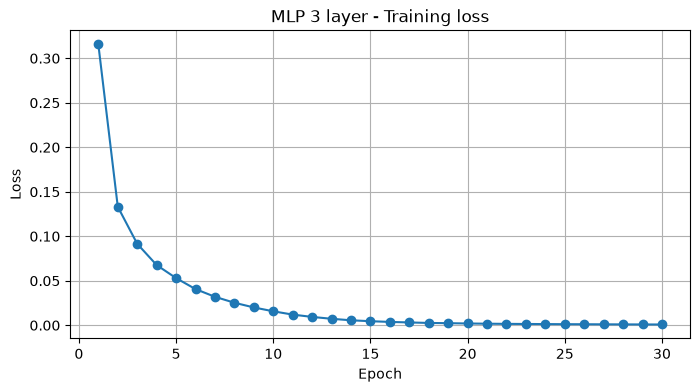

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(model2.loss_history) + 1), model2.loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP 3 layer - Training loss")
plt.grid(True)
plt.show()

In [8]:
y_pred2 = model2.predict(x_test)
evaluate(y_test, y_pred2)

Accuracy: 0.9819
Digit  Precision  Recall  F1-score
    0  0.9828     0.9898  0.9863
    1  0.9938     0.9938  0.9938
    2  0.9805     0.9767  0.9786
    3  0.9812     0.9812  0.9812
    4  0.9767     0.9817  0.9792
    5  0.9831     0.9787  0.9809
    6  0.9823     0.9823  0.9823
    7  0.9834     0.9825  0.9830
    8  0.9784     0.9754  0.9769
    9  0.9752     0.9752  0.9752
Precision-macro: 0.9817
Recall-macro: 0.9817
F1-macro: 0.9817


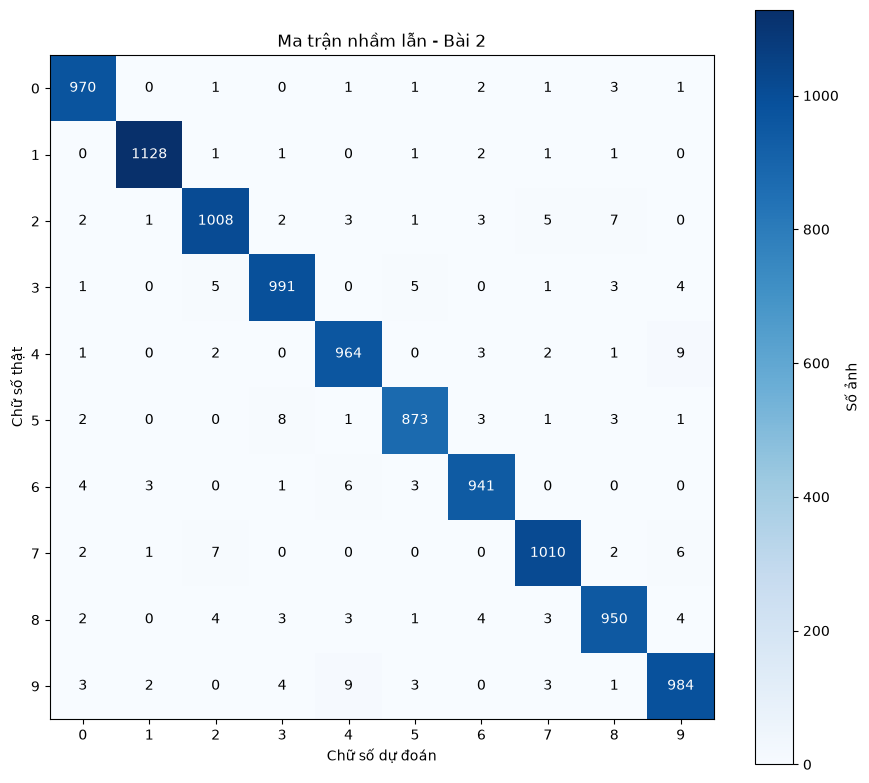

In [9]:
confusion2 = np.zeros((10, 10), dtype=int)
np.add.at(confusion2, (y_test, y_pred2), 1)

plt.figure(figsize=(9, 8))
plt.imshow(confusion2, cmap="Blues")
plt.colorbar(label="Số ảnh")
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Chữ số dự đoán")
plt.ylabel("Chữ số thật")
plt.title("Ma trận nhầm lẫn - Bài 2")
for row in range(10):
    for col in range(10):
        color = "white" if confusion2[row, col] > confusion2.max() / 2 else "black"
        plt.text(col, row, confusion2[row, col], ha="center", va="center", color=color)
plt.tight_layout()
plt.show()

Nhận xét bài 2

Sau 30 epoch, loss còn khoảng 0.0009. Accuracy trên tập test đạt 98.19%, F1-macro đạt 0.9817. Cả 10 chữ số đều có F1 cao hơn mô hình ở bài 1.

Số 0 và 1 vẫn có kết quả tốt nhất. Số 1 chỉ sai 7 ảnh trong 1135 ảnh. Các số 3, 5, 6 và 7 đều có F1 trên 0.98. Lỗi nhầm số 5 thành 3 giảm từ 46 ảnh ở bài 1 xuống còn 8 ảnh.

Các số 2, 4 và 8 có F1 khoảng 0.977 đến 0.979. Có 7 ảnh số 2 bị đoán thành 8 và 9 ảnh số 4 bị đoán thành 9. Số 9 có F1 thấp nhất là 0.9752, với 9 ảnh bị đoán thành 4.

MLP 3 lớp cho kết quả tốt hơn MLP một lớp. Các lỗi nhầm giữa những chữ số đã giảm, dù cặp 4 và 9 vẫn còn bị nhầm với nhau.